## Website

https://gymnasium.farama.org/

## Basic usage

### Workflow

**make, reset, step, render**

In [1]:
import gymnasium as gym

env = gym.make("LunarLander-v2", render_mode="human")
observation, info = env.reset(seed=42)
for _ in range(1000):
    action = env.action_space.sample()  # this is where you would insert your policy
    observation, reward, terminated, truncated, info = env.step(action)

    if terminated or truncated:
        observation, info = env.reset()
env.close()

### Initializing enviroments

In [2]:
import gymnasium as gym
env = gym.make('CartPole-v1')

In [3]:
observation, info = env.reset(seed=98)
print(observation, info)

[ 0.04436556  0.03513309 -0.04278005 -0.02088692] {}


### Action and observation spaces

In [4]:
import numpy as np
from gymnasium.spaces import Box, Discrete, Dict, Tuple, MultiBinary, MultiDiscrete

observation_space = Box(low=-1.0, high=2.0, shape=(3,), dtype=np.float32)
observation_space.sample()

observation_space = Discrete(4)
observation_space.sample()

observation_space = Discrete(5, start=-2)
observation_space.sample()

observation_space = Dict({"position": Discrete(2), "velocity": Discrete(3)})
observation_space.sample()

observation_space = Tuple((Discrete(2), Discrete(3)))
observation_space.sample()

observation_space = MultiBinary(5)
observation_space.sample()

observation_space = MultiDiscrete([ 5, 2, 2 ])
observation_space.sample()

array([3, 1, 1], dtype=int64)

### Modifying the enviroment

In [7]:
import gymnasium as gym
from gymnasium.wrappers import FlattenObservation
env = gym.make("CarRacing-v2")
print(env.observation_space.shape)

wrapped_env = FlattenObservation(env)
print(wrapped_env.observation_space.shape)


(96, 96, 3)
(27648,)


In [10]:
wrapped_env

<FlattenObservation<TimeLimit<OrderEnforcing<PassiveEnvChecker<CarRacing<CarRacing-v2>>>>>>

In [11]:
wrapped_env.unwrapped

## Env

### Methods

**step**

Parameters:

    action
    
Returns:

    observation, reward, terminated, truncated, info

**reset**

Parameters:

    seed, options
    
Returns:

    observation, info

**render**

不在单独的语句中指定，在

env = gym.make(reder_mode='')中指定

### Attributes

In [12]:
import gymnasium as gym

env = gym.make("LunarLander-v2", render_mode="human")

In [13]:
env.action_space

Discrete(4)

In [14]:
env.observation_space

Box([-90.        -90.         -5.         -5.         -3.1415927  -5.
  -0.         -0.       ], [90.        90.         5.         5.         3.1415927  5.
  1.         1.       ], (8,), float32)

In [15]:
env.reward_range

(-inf, inf)

In [16]:
env.spec

EnvSpec(id='LunarLander-v2', entry_point='gymnasium.envs.box2d.lunar_lander:LunarLander', reward_threshold=200, nondeterministic=False, max_episode_steps=1000, order_enforce=True, autoreset=False, disable_env_checker=False, apply_api_compatibility=False, kwargs={'render_mode': 'human'}, namespace=None, name='LunarLander', version=2, additional_wrappers=(), vector_entry_point=None)

In [17]:
env.metadata

{'render_modes': ['human', 'rgb_array'], 'render_fps': 50}

In [18]:
env.np_random

Generator(PCG64) at 0x1B93AAC3680

### Others

close

unwrapped

np_random

## Register and make

获取已经注册的环境：

In [2]:
import gymnasium as gym

gym.envs.registry.keys()

dict_keys(['CartPole-v0', 'CartPole-v1', 'MountainCar-v0', 'MountainCarContinuous-v0', 'Pendulum-v1', 'Acrobot-v1', 'CartPoleJax-v0', 'CartPoleJax-v1', 'PendulumJax-v0', 'LunarLander-v2', 'LunarLanderContinuous-v2', 'BipedalWalker-v3', 'BipedalWalkerHardcore-v3', 'CarRacing-v2', 'Blackjack-v1', 'FrozenLake-v1', 'FrozenLake8x8-v1', 'CliffWalking-v0', 'Taxi-v3', 'Jax-Blackjack-v0', 'Reacher-v2', 'Reacher-v4', 'Pusher-v2', 'Pusher-v4', 'InvertedPendulum-v2', 'InvertedPendulum-v4', 'InvertedDoublePendulum-v2', 'InvertedDoublePendulum-v4', 'HalfCheetah-v2', 'HalfCheetah-v3', 'HalfCheetah-v4', 'Hopper-v2', 'Hopper-v3', 'Hopper-v4', 'Swimmer-v2', 'Swimmer-v3', 'Swimmer-v4', 'Walker2d-v2', 'Walker2d-v3', 'Walker2d-v4', 'Ant-v2', 'Ant-v3', 'Ant-v4', 'Humanoid-v2', 'Humanoid-v3', 'Humanoid-v4', 'HumanoidStandup-v2', 'HumanoidStandup-v4', 'GymV21Environment-v0', 'GymV26Environment-v0'])

### make

Parameters:
    
    id, max_episode_steps, autoreset ......

Returns:

    instance of enviroment

### register

### spec

### pprint_registry

In [3]:
import gymnasium as gym

gym.pprint_registry()

===== classic_control =====
Acrobot-v1             CartPole-v0            CartPole-v1
MountainCar-v0         MountainCarContinuous-v0 Pendulum-v1
===== phys2d =====
CartPoleJax-v0         CartPoleJax-v1         PendulumJax-v0
===== box2d =====
BipedalWalker-v3       BipedalWalkerHardcore-v3 CarRacing-v2
LunarLander-v2         LunarLanderContinuous-v2
===== toy_text =====
Blackjack-v1           CliffWalking-v0        FrozenLake-v1
FrozenLake8x8-v1       Taxi-v3
===== tabular =====
Jax-Blackjack-v0
===== mujoco =====
Ant-v2                 Ant-v3                 Ant-v4
HalfCheetah-v2         HalfCheetah-v3         HalfCheetah-v4
Hopper-v2              Hopper-v3              Hopper-v4
Humanoid-v2            Humanoid-v3            Humanoid-v4
HumanoidStandup-v2     HumanoidStandup-v4     InvertedDoublePendulum-v2
InvertedDoublePendulum-v4 InvertedPendulum-v2    InvertedPendulum-v4
Pusher-v2              Pusher-v4              Reacher-v2
Reacher-v4             Swimmer-v2             Swimmer

### Core variables

#### gym.envs.registration.EnvSpec

In [6]:
import gymnasium as gym

gym.envs.registration.EnvSpec("LunarLander-v2")

EnvSpec(id='LunarLander-v2', entry_point=None, reward_threshold=None, nondeterministic=False, max_episode_steps=None, order_enforce=True, autoreset=False, disable_env_checker=False, apply_api_compatibility=False, kwargs={}, namespace=None, name='LunarLander', version=2, additional_wrappers=(), vector_entry_point=None)

#### gym.envs.registration.registry

In [7]:
import gymnasium as gym

gym.envs.registration.registry

{'CartPole-v0': EnvSpec(id='CartPole-v0', entry_point='gymnasium.envs.classic_control.cartpole:CartPoleEnv', reward_threshold=195.0, nondeterministic=False, max_episode_steps=200, order_enforce=True, autoreset=False, disable_env_checker=False, apply_api_compatibility=False, kwargs={}, namespace=None, name='CartPole', version=0, additional_wrappers=(), vector_entry_point='gymnasium.envs.classic_control.cartpole:CartPoleVectorEnv'),
 'CartPole-v1': EnvSpec(id='CartPole-v1', entry_point='gymnasium.envs.classic_control.cartpole:CartPoleEnv', reward_threshold=475.0, nondeterministic=False, max_episode_steps=500, order_enforce=True, autoreset=False, disable_env_checker=False, apply_api_compatibility=False, kwargs={}, namespace=None, name='CartPole', version=1, additional_wrappers=(), vector_entry_point='gymnasium.envs.classic_control.cartpole:CartPoleVectorEnv'),
 'MountainCar-v0': EnvSpec(id='MountainCar-v0', entry_point='gymnasium.envs.classic_control.mountain_car:MountainCarEnv', reward_t

#### gym.envs.registration.current_namespace

In [12]:
import gymnasium as gym

print(gym.envs.registration.current_namespace)

None


## Spaces

Parameters:
    
    shape, dtype, seed

### Attributes

In [14]:
import gymnasium as gym

env = gym.make("LunarLander-v2")

space = env.action_space

space

Discrete(4)

In [15]:
space.shape

()

In [16]:
space.dtype

dtype('int64')

In [17]:
space.is_np_flattenable

True

### Methods

In [18]:
import gymnasium as gym

env = gym.make("LunarLander-v2")

space = env.action_space

space

Discrete(4)

In [29]:
space.sample()

0

In [32]:
space.contains(3)

True

In [34]:
space.seed(98)

[98]

### Fundamental spaces

Box

Discrete

MultiBinary

MultiDiscrete

Text

In [45]:
import gymnasium as gym
import numpy as np
from gym.spaces import MultiDiscrete

a = MultiDiscrete(np.array([[1,2], [3,4]]))

In [47]:
a.sample()

array([[0, 0],
       [1, 2]], dtype=int64)

### Composite spaces

Dict

Tuple

Sequence

Graph

## Wrappers

https://gymnasium.farama.org/api/wrappers/#gymnasium-wrappers

In [10]:
import gymnasium as gym
from gymnasium.wrappers import RescaleAction
base_env = gym.make("BipedalWalker-v3")
base_env.action_space

Box(-1.0, 1.0, (4,), float32)

In [11]:
wrapped_env = RescaleAction(base_env, min_action=0, max_action=1)
wrapped_env.action_space

Box(-1.0, 1.0, (4,), float32)

In [12]:
wrapped_env

<RescaleAction<TimeLimit<OrderEnforcing<PassiveEnvChecker<BipedalWalker<BipedalWalker-v3>>>>>>

### Attributes

In [13]:
wrapped_env.action_space

Box(-1.0, 1.0, (4,), float32)

In [14]:
wrapped_env.observation_space

Box([-3.1415927 -5.        -5.        -5.        -3.1415927 -5.
 -3.1415927 -5.        -0.        -3.1415927 -5.        -3.1415927
 -5.        -0.        -1.        -1.        -1.        -1.
 -1.        -1.        -1.        -1.        -1.        -1.       ], [3.1415927 5.        5.        5.        3.1415927 5.        3.1415927
 5.        5.        3.1415927 5.        3.1415927 5.        5.
 1.        1.        1.        1.        1.        1.        1.
 1.        1.        1.       ], (24,), float32)

In [15]:
wrapped_env.reward_range

(-inf, inf)

In [16]:
wrapped_env.spec

EnvSpec(id='BipedalWalker-v3', entry_point='gymnasium.envs.box2d.bipedal_walker:BipedalWalker', reward_threshold=300, nondeterministic=False, max_episode_steps=1600, order_enforce=True, autoreset=False, disable_env_checker=False, apply_api_compatibility=False, kwargs={}, namespace=None, name='BipedalWalker', version=3, additional_wrappers=(WrapperSpec(name='RescaleAction', entry_point='gymnasium.wrappers.rescale_action:RescaleAction', kwargs={'min_action': 0, 'max_action': 1}),), vector_entry_point=None)

In [17]:
wrapped_env.metadata

{'render_modes': ['human', 'rgb_array'], 'render_fps': 50}

In [18]:
wrapped_env.np_random

Generator(PCG64) at 0x1F8495BAB20

## Vector

### Without vector

In [19]:
import gymnasium as gym

env = gym.make("CartPole-v1", render_mode="human")
observation, info = env.reset(seed=42)
for _ in range(1000):
    action = env.action_space.sample()  # this is where you would insert your policy
    observation, reward, terminated, truncated, info = env.step(action)

    if terminated or truncated:
       observation, info = env.reset()
env.close()

In [22]:
observation

array([ 0.12149312,  0.76270247, -0.08066519, -1.034951  ], dtype=float32)

### With vector

In [3]:
import gymnasium as gym
import numpy as np
envs = gym.vector.make("CartPole-v1", num_envs=3)
_ = envs.reset(seed=42)
actions = np.array([1, 0, 1])
observations, rewards, termination, truncation, infos = envs.step(actions)
observations

array([[ 0.02727336,  0.18847767,  0.03625453, -0.26141977],
       [ 0.01431748, -0.24002443, -0.04731862,  0.3110827 ],
       [-0.03822722,  0.1710671 , -0.00848456, -0.2487226 ]],
      dtype=float32)

In [4]:
rewards

array([1., 1., 1.])

In [5]:
termination

array([False, False, False])

In [7]:
infos

{}

### Attributes

In [10]:
envs.action_space

MultiDiscrete([2 2 2])

In [11]:
envs.single_action_space

Discrete(2)

In [12]:
envs.observation_space

Box([[-4.8000002e+00 -3.4028235e+38 -4.1887903e-01 -3.4028235e+38]
 [-4.8000002e+00 -3.4028235e+38 -4.1887903e-01 -3.4028235e+38]
 [-4.8000002e+00 -3.4028235e+38 -4.1887903e-01 -3.4028235e+38]], [[4.8000002e+00 3.4028235e+38 4.1887903e-01 3.4028235e+38]
 [4.8000002e+00 3.4028235e+38 4.1887903e-01 3.4028235e+38]
 [4.8000002e+00 3.4028235e+38 4.1887903e-01 3.4028235e+38]], (3, 4), float32)

In [13]:
envs.single_observation_space

Box([-4.8000002e+00 -3.4028235e+38 -4.1887903e-01 -3.4028235e+38], [4.8000002e+00 3.4028235e+38 4.1887903e-01 3.4028235e+38], (4,), float32)

## Utils

### Play

In [16]:
import gymnasium as gym
from gymnasium.utils.play import play
play(gym.make("CarRacing-v2", render_mode="rgb_array"), keys_to_action={  
                                               "w": np.array([0, 0.7, 0]),
                                               "a": np.array([-1, 0, 0]),
                                               "s": np.array([0, 0, 1]),
                                               "d": np.array([1, 0, 0]),
                                               "wa": np.array([-1, 0.7, 0]),
                                               "dw": np.array([1, 0.7, 0]),
                                               "ds": np.array([1, 0, 1]),
                                               "as": np.array([-1, 0, 1]),
                                              }, noop=np.array([0,0,0]))

### Save vedio

In [12]:
import gymnasium as gym
from gymnasium.utils.save_video import save_video
env = gym.make("FrozenLake-v1", render_mode="rgb_array_list")
_ = env.reset()
step_starting_index = 0
episode_index = 0
for step_index in range(199): 
        action = env.action_space.sample()
        _, _, terminated, truncated, _ = env.step(action)

        if terminated or truncated:
            save_video(
                env.render(),
                "videos",
                fps=env.metadata["render_fps"],
                step_starting_index=step_starting_index,
                episode_index=episode_index
            )
            step_starting_index = step_index + 1
            episode_index += 1
            print(episode_index)
            env.reset()
env.close()

Moviepy - Building video D:\颜昺阳\4. 专业积累\Python\Packages\videos/rl-video-episode-0.mp4.
Moviepy - Writing video D:\颜昺阳\4. 专业积累\Python\Packages\videos/rl-video-episode-0.mp4



Moviepy - Done !
Moviepy - video ready D:\颜昺阳\4. 专业积累\Python\Packages\videos/rl-video-episode-0.mp4
1
Moviepy - Building video D:\颜昺阳\4. 专业积累\Python\Packages\videos/rl-video-episode-1.mp4.
Moviepy - Writing video D:\颜昺阳\4. 专业积累\Python\Packages\videos/rl-video-episode-1.mp4



Moviepy - Done !
Moviepy - video ready D:\颜昺阳\4. 专业积累\Python\Packages\videos/rl-video-episode-1.mp4
2
3
4
5
6
7
8
Moviepy - Building video D:\颜昺阳\4. 专业积累\Python\Packages\videos/rl-video-episode-8.mp4.
Moviepy - Writing video D:\颜昺阳\4. 专业积累\Python\Packages\videos/rl-video-episode-8.mp4



Moviepy - Done !
Moviepy - video ready D:\颜昺阳\4. 专业积累\Python\Packages\videos/rl-video-episode-8.mp4
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27


## env-cartpole

In [18]:
import gymnasium as gym

env = gym.make('CartPole-v1', render_mode="human")
observation, info = env.reset(seed=98)
for _ in range(1000):
    action = env.action_space.sample()  # this is where you would insert your policy
    observation, reward, terminated, truncated, info = env.step(action)
    
    print(reward)

    if terminated or truncated:
        observation, info = env.reset()
env.close()

1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0


## env-forzen lake

In [1]:
import gymnasium as gym

env = gym.make('FrozenLake-v1', is_slippery=True, render_mode='human')
observation, info = env.reset(seed=98)

for i in range(100):
    
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    
    if terminated or truncated:
        observation, info = env.reset()

env.close()

## env-GridWorld

In [1]:
import gymnasium as gym

env = gym.make("MiniGrid-Empty-5x5-v0", render_mode="human")
observation, info = env.reset(seed=42)
for _ in range(1000):
    action = policy(observation)  # User-defined policy function
    observation, reward, terminated, truncated, info = env.step(action)

    if terminated or truncated:
        observation, info = env.reset()
env.close()

NameNotFound: Environment `MiniGrid-Empty-5x5` doesn't exist.

## 导入自定义环境

### gym-examples

使用官网的gym-examples会遇到一些错误，这是因为这个例子中的所有__init__.py文件都是使用旧的gym，将gym替换成gymnasium就可以运行

### 导入环境的两种方式

导入环境只有两种方式，因为register的entry_point要依赖于一个package。

第一种方式是将环境模块复制到gymnasium模块当中，然后在__init__文件中进行register。（相对来说比较简单，参考gym-examples中的__init__.py文件就可以配置完成）

第二种是安装本地包，然后在本地包中进行register。（这个最复杂，参考gym-examples文件夹中的文件）(**推荐**)

**虽然使用环境变量可以将环境临时添加到注册列表，但是在运行的过程中gym会识别出环境所在的文件不是模块进行报错。**

### 注册环境-本地包（成功）

环境名：GridWorld_v0

文件夹结构：

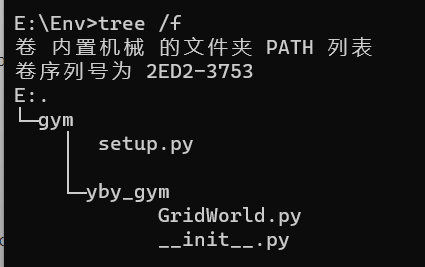

In [1]:
import yby_gym
import gymnasium as gym

gym.pprint_registry()

===== classic_control =====
Acrobot-v1             CartPole-v0            CartPole-v1
MountainCar-v0         MountainCarContinuous-v0 Pendulum-v1
===== phys2d =====
CartPoleJax-v0         CartPoleJax-v1         PendulumJax-v0
===== box2d =====
BipedalWalker-v3       BipedalWalkerHardcore-v3 CarRacing-v2
LunarLander-v2         LunarLanderContinuous-v2
===== toy_text =====
Blackjack-v1           CliffWalking-v0        FrozenLake-v1
FrozenLake8x8-v1       Taxi-v3
===== tabular =====
Jax-Blackjack-v0
===== mujoco =====
Ant-v2                 Ant-v3                 Ant-v4
HalfCheetah-v2         HalfCheetah-v3         HalfCheetah-v4
Hopper-v2              Hopper-v3              Hopper-v4
Humanoid-v2            Humanoid-v3            Humanoid-v4
HumanoidStandup-v2     HumanoidStandup-v4     InvertedDoublePendulum-v2
InvertedDoublePendulum-v4 InvertedPendulum-v2    InvertedPendulum-v4
Pusher-v2              Pusher-v4              Reacher-v2
Reacher-v4             Swimmer-v2             Swimmer

In [2]:
import gymnasium as gym

env = gym.make("GridWorld-v0", render_mode="human")
observation, info = env.reset(seed=42)
for _ in range(100):
    action = env.action_space.sample()  # this is where you would insert your policy
    observation, reward, terminated, truncated, info = env.step(action)

    if terminated or truncated:
        observation, info = env.reset()
env.close()

### 注册环境-环境变量（失败）

以第三种方式为例

环境GridWorldEnv所在的py文件为："C:\Users\Flyby\Desktop\gym-examples\gym_examples\envs\grid_world.py"

In [2]:
import sys
import gymnasium as gym
from gymnasium.envs.registration import register

sys.path.append(r"C:\Users\Flyby\Desktop\gym-examples\gym_examples\envs")
register(id='test-v3', entry_point='grid_world:GridWorldEnv')
gym.pprint_registry()

===== classic_control =====
Acrobot-v1             CartPole-v0            CartPole-v1
MountainCar-v0         MountainCarContinuous-v0 Pendulum-v1
===== phys2d =====
CartPoleJax-v0         CartPoleJax-v1         PendulumJax-v0
===== box2d =====
BipedalWalker-v3       BipedalWalkerHardcore-v3 CarRacing-v2
LunarLander-v2         LunarLanderContinuous-v2
===== toy_text =====
Blackjack-v1           CliffWalking-v0        FrozenLake-v1
FrozenLake8x8-v1       Taxi-v3
===== tabular =====
Jax-Blackjack-v0
===== mujoco =====
Ant-v2                 Ant-v3                 Ant-v4
HalfCheetah-v2         HalfCheetah-v3         HalfCheetah-v4
Hopper-v2              Hopper-v3              Hopper-v4
Humanoid-v2            Humanoid-v3            Humanoid-v4
HumanoidStandup-v2     HumanoidStandup-v4     InvertedDoublePendulum-v2
InvertedDoublePendulum-v4 InvertedPendulum-v2    InvertedPendulum-v4
Pusher-v2              Pusher-v4              Reacher-v2
Reacher-v4             Swimmer-v2             Swimmer

In [5]:
import gymnasium as gym

env = gym.make("test-v3", render_mode="human")
observation, info = env.reset(seed=42)
for _ in range(1000):
    action = env.action_space.sample()  # this is where you would insert your policy
    observation, reward, terminated, truncated, info = env.step(action)

    if terminated or truncated:
        observation, info = env.reset()
env.close()

ModuleNotFoundError: No module named 'grid_world'

## sample seed

**deepcopy可以重置seed为None**

In [ ]:
import gymnasium as gym
from yby.y_control import Y

class Y_simple(gym.Env, Y):

    def __init__(self, **kargs):
        Y.__init__(self)
        for i, v in locals().items():
            setattr(self, i, v)

        self.name = 'Y_simple'
        self.start()

        self.reset()


    def input_default(self):

        dargs = {
            'obs_low':[150, 100, 4, 0],
            'obs_high':[200, 150, 14, 15],
            'seed':98,
        }

        return dargs


    def input_pro(self):

        import numpy as np
        from gymnasium.spaces import Box
        from gym.utils import seeding
        from copy import deepcopy

        self.observation_space = Box(low=np.array(self.obs_low, dtype=np.float64),
                                     high=np.array(self.obs_high, dtype=np.float64),
                                     shape=np.array(self.obs_low).shape,
                                     dtype=np.float64)
        obs = deepcopy(self.observation_space)
        obs.seed(self.seed)
        print('yby1', obs.sample())



    def reset(self):
        super().reset(seed=self.seed)

        from copy import deepcopy



        #observation = self.np_random.integers(low=[150, 100, 4, 0], high=[])
        info = {}
        #self.observation_space.seed(self.seed)
        #obs = deepcopy(self.observation_space)
        #obs.seed(self.seed)
        print('yby2', self.observation_space.sample())

        #return (observation, info)



    def step(self, action):

        return (observation, reward, terminated, truncated, info)

Y_simple()

## error

### pip install box2d

如果安装box2d错误，显示需要vc++14.0，千万不要去安装vc++，去box2d的whl安装即可

gym找不到那个包就去安装哪个包就可以

下载whl：https://www.lfd.uci.edu/~gohlke/pythonlibs/